   pclass survived                                             name     sex  \
0       1        1                    Allen, Miss. Elisabeth Walton  female   
1       1        1                   Allison, Master. Hudson Trevor    male   
2       1        0                     Allison, Miss. Helen Loraine  female   
3       1        0             Allison, Mr. Hudson Joshua Creighton    male   
4       1        0  Allison, Mrs. Hudson J C (Bessie Waldo Daniels)  female   

       age  sibsp  parch  ticket      fare    cabin embarked boat   body  \
0  29.0000      0      0   24160  211.3375       B5        S    2    NaN   
1   0.9167      1      2  113781  151.5500  C22 C26        S   11    NaN   
2   2.0000      1      2  113781  151.5500  C22 C26        S  NaN    NaN   
3  30.0000      1      2  113781  151.5500  C22 C26        S  NaN  135.0   
4  25.0000      1      2  113781  151.5500  C22 C26        S  NaN    NaN   

                         home.dest  
0                     St Louis,

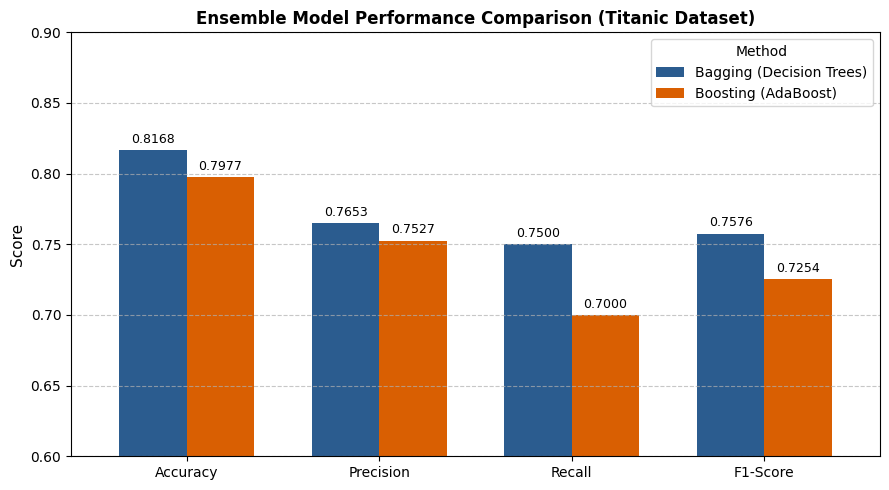

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ==========================================
# Task 1: Load and Preprocess Titanic Dataset
# ==========================================
# Load Titanic dataset from OpenML
titanic = fetch_openml('titanic', version=1, as_frame=True)
df = titanic.frame
print(df.head(5))
# Select key features and target
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
X = df[features]
y = df['survived'].astype(int)  # Convert target to integer (0 or 1)

# Define preprocessing pipelines
numeric_features = ['age', 'fare', 'sibsp', 'parch']
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_features = ['pclass', 'sex', 'embarked']
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Split dataset into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Apply preprocessing
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)


# ==========================================
# Task 2: Implement Bagging (Bootstrap Aggregating)
# ==========================================
# Deep Decision Trees tend to have high variance / overfit individually
base_tree = DecisionTreeClassifier(max_depth=None, random_state=42)

bagging_model = BaggingClassifier(
    estimator=base_tree,
    n_estimators=100,
    max_samples=1.0,
    max_features=1.0,
    bootstrap=True,
    random_state=42
)

bagging_model.fit(X_train_prep, y_train)
y_pred_bag = bagging_model.predict(X_test_prep)


# ==========================================
# Task 3: Implement Boosting (AdaBoost)
# ==========================================
# Boosting uses shallow weak learners (Decision Stumps) sequentially
weak_stump = DecisionTreeClassifier(max_depth=1, random_state=42)

boosting_model = AdaBoostClassifier(
    estimator=weak_stump,
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

boosting_model.fit(X_train_prep, y_train)
y_pred_boost = boosting_model.predict(X_test_prep)


# ==========================================
# Task 4: Compare Performance Metrics
# ==========================================
def compute_metrics(y_true, y_pred, name):
    return {
        'Method': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred)
    }

results = [
    compute_metrics(y_test, y_pred_bag, "Bagging (Decision Trees)"),
    compute_metrics(y_test, y_pred_boost, "Boosting (AdaBoost)")
]

results_df = pd.DataFrame(results)
print("--- ENSEMBLE PERFORMANCE COMPARISON ---")
print(results_df.round(4).to_string(index=False))

# ==========================================
# Task 5: Visualize Performance Comparison
# ==========================================
# Reshape DataFrame for grouped bar chart plotting
df_plot = results_df.set_index('Method').T

# Plot grouped bar chart
ax = df_plot.plot(
    kind='bar', 
    figsize=(9, 5), 
    width=0.7, 
    color=['#2b5c8f', '#d95f02'], 
    rot=0
)

# Customization and labels
plt.title('Ensemble Model Performance Comparison (Titanic Dataset)', fontsize=12, fontweight='bold')
plt.ylabel('Score', fontsize=11)
plt.ylim(0.6, 0.9)  # Zoomed y-axis range to emphasize metric differences
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Method', loc='upper right')

# Display exact numeric values on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.4f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()